In [ ]:
pip install torch torchvision

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')
!unzip /content/drive/MyDrive/Forager_Data.zip -d /content/dataset

Mounted at /content/drive/
Archive:  /content/drive/MyDrive/Forager_Data.zip
   creating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/
   creating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0001.jpg  
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0002.jpg  
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0003.jpg  
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0004.jpg  
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0005.jpg  
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0006.jpg  
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0008.jpg  
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0019.jpg  
  inflating: /content/dataset/Volumes/T7/Forager_Data_No_CSV/wild-garlic/0020.jpg  
  inflating: /content/dataset/V

In [ ]:
import torch
# Wrapper class to apply transforms to a Subset
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

    def __len__(self):
        return len(self.subset)

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split


# Train transform includes augmentation
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224), #random crop position in the image, still resizes to 224x224
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1), #different lighting
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)), #shifting image around
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Test transform doesn't include augmentation
test_transform = transforms.Compose([
    transforms.Resize(255),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

dataset = datasets.ImageFolder(root='/content/dataset/Volumes/T7/Forager_Data_No_CSV')
train_dataset, test_dataset = torch.utils.data.random_split(dataset, [0.8, 0.2])

# Apply different transforms
train_data = TransformedSubset(train_dataset, train_transform)
test_data = TransformedSubset(test_dataset, test_transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

training examples


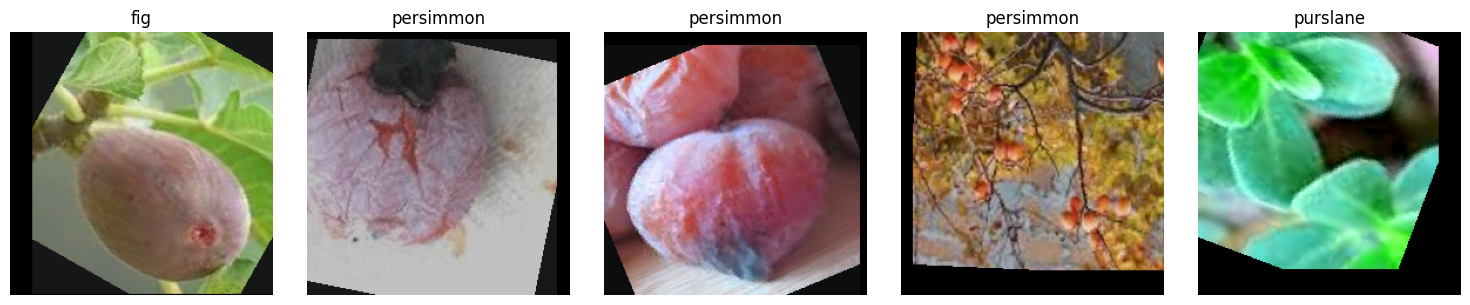

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("training examples")
images, labels = next(iter(train_loader))
class_names = dataset.classes

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    ax = axes[i]
    img = images[i].numpy().transpose((1, 2, 0))
    # Undo normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    ax.set_title(class_names[labels[i].item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
print(class_names)

['fig', 'japanese-honeysuckle', 'mulberry', 'osmanthus', 'persimmon', 'purslane', 'ramps', 'rosemary', 'wild-garlic', 'wild-raspberry']


testing examples


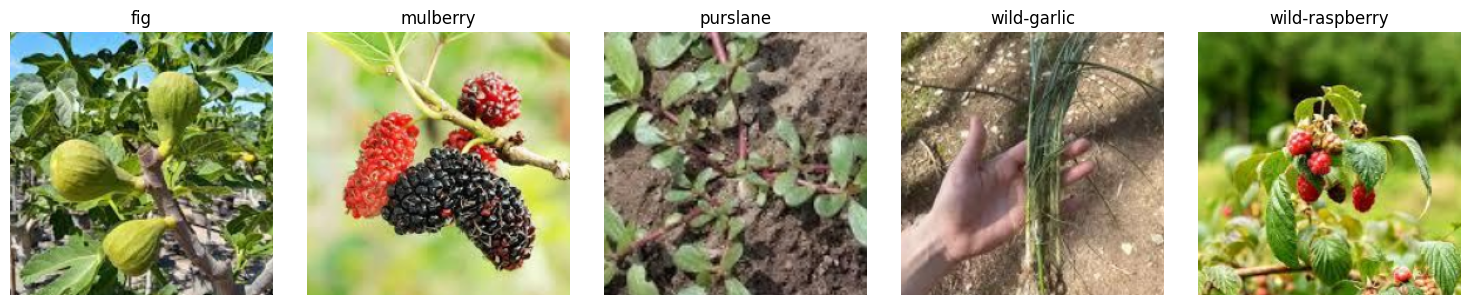

In [ ]:
print("testing examples")
images, labels = next(iter(test_loader))
class_names = dataset.classes

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    ax = axes[i]
    img = images[i].numpy().transpose((1, 2, 0))
    # Undo normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    ax.set_title(class_names[labels[i].item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
#verifying right input features size for mobilenet
print(images.shape)

torch.Size([32, 3, 224, 224])


In [ ]:
#boilerplate for mobilenetv3
import torchvision.models as models

# Load MobileNetV3-Large pretrained on ImageNet
mobilenet_v3_large = models.mobilenet_v3_large(pretrained=True)

# Load MobileNetV3-Small pretrained on ImageNet
mobilenet_v3_small = models.mobilenet_v3_small(pretrained=True)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Large_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Large_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 21.1M/21.1M [00:00<00:00, 84.5MB/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1`. 

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 122MB/s]


In [ ]:
#fine-tune mobilenet
import torch.nn as nn
#Modify the final layer for a custom number of classes (e.g., 10)
mobilenet_v3_small.classifier[3] = nn.Linear(in_features=1024, out_features=10)
mobilenet_v3_large.classifier[3] = nn.Linear(in_features=1280, out_features=10)

In [ ]:
#train large mobilenet
import torch.optim as optim

# Use GPU if possible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mobilenet_v3_large = mobilenet_v3_large.to(device)
mobilenet_v3_large.train()

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.Adam(mobilenet_v3_large.parameters(), lr=0.0001)

# Training loop
num_epochs = 10
for epoch in range(num_epochs):
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs = mobilenet_v3_large(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}]", f"Loss: {running_loss/len(train_loader):.4f}")

Epoch [1/10] Loss: 2.0367
Epoch [2/10] Loss: 1.5113
Epoch [3/10] Loss: 1.1893
Epoch [4/10] Loss: 1.0757
Epoch [5/10] Loss: 0.9796
Epoch [6/10] Loss: 0.9294
Epoch [7/10] Loss: 0.8817
Epoch [8/10] Loss: 0.8493
Epoch [9/10] Loss: 0.8098
Epoch [10/10] Loss: 0.8460


In [ ]:
#evaluate model
#baseling loss using cross entropy is log(10) = 2.3

mobilenet_v3_large.eval()  # Set the model to evaluation mode

correct = 0
total = 0
all_preds = []
all_labels = []
validation_loss = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = mobilenet_v3_large(inputs)
        loss = criterion(outputs, labels)

        validation_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        # Save for metrics (move to CPU)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

validation_loss /= len(test_loader)
accuracy = 100 * correct / total

print(f"Validation Loss: {validation_loss:.4f}")
print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Loss: 0.7608
Validation Accuracy: 91.43%


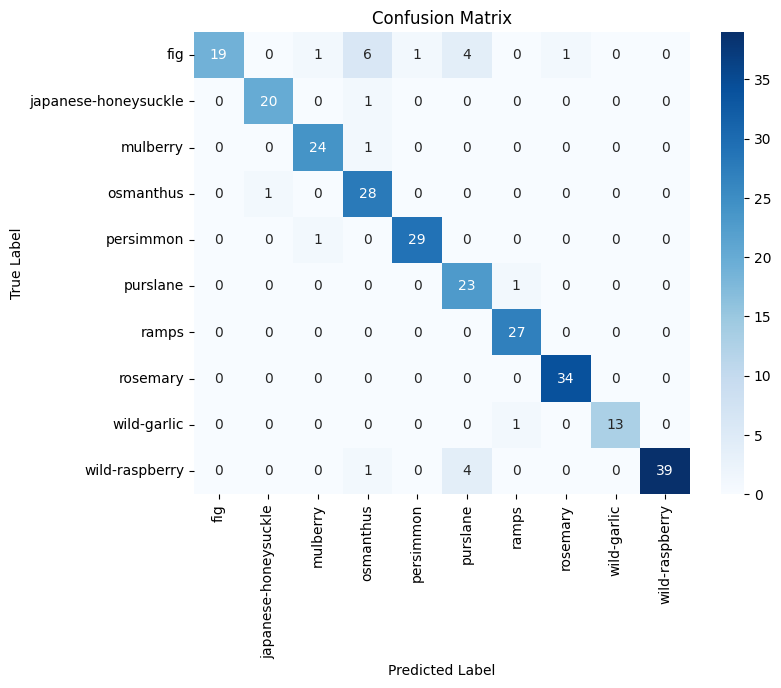

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
!pip install coremltools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 9.4 MB/s eta 0:00:00


In [ ]:
device = torch.device("cpu")
mobilenet_v3_large = mobilenet_v3_large.to(device)

In [ ]:
class ModelWithSoftmax(torch.nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base = base_model

    def forward(self, x):
        logits = self.base(x)
        return torch.softmax(logits, dim=1)  # converts logits to probabilities

In [ ]:
export_model = ModelWithSoftmax(mobilenet_v3_large)
export_model.eval()

ModelWithSoftmax(
  (base): MobileNetV3(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
            (2): ReLU(inplace=True)
          )
          (1): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          )
        )
      )
      (2): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivat

In [ ]:
import coremltools as ct

example_input = torch.rand(1, 3, 224, 224) #batch, channels (RGB), image height, image width
traced_model = torch.jit.trace(export_model, example_input)
#dataset.classes
class_names = ['fig', 'japanese-honeysuckle', 'mulberry', 'osmanthus', 'persimmon', 'purslane', 'ramps', 'rosemary', 'wild-garlic', 'wild-raspberry']

mlmodel = ct.convert(
    traced_model,
    inputs = [ct.TensorType(shape=example_input.shape)],
    classifier_config=ct.ClassifierConfig(class_labels=class_names),
    minimum_deployment_target=ct.target.iOS15
)


Running MIL default pipeline:   0%|          | 0/95 [00:00<?, ? passes/s]/usr/local/lib/python3.12/dist-packages/coremltools/converters/mil/mil/passes/defs/preprocess.py:245: UserWarning: Input, 'x.1', of the source model, has been renamed to 'x_1' in the Core ML model.
  warnings.warn(msg.format(var.name, new_name))
/usr/local/lib/python3.12/dist-packages/coremltools/converters/mil/mil/passes/defs/preprocess.py:273: UserWarning: Output, '931', of the source model, has been renamed to 'var_931' in the Core ML model.
  warnings.warn(msg.format(var.name, new_name))
Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 107.73 passes/s]


In [ ]:
print(mlmodel)

input {
  name: "x_1"
  type {
    multiArrayType {
      shape: 1
      shape: 3
      shape: 224
      shape: 224
      dataType: FLOAT32
    }
  }
}
output {
  name: "classLabel"
  type {
    stringType {
    }
  }
}
output {
  name: "classLabel_probs"
  type {
    dictionaryType {
      stringKeyType {
      }
    }
  }
}
predictedFeatureName: "classLabel"
predictedProbabilitiesName: "classLabel_probs"
metadata {
  userDefined {
    key: "com.github.apple.coremltools.version"
    value: "9.0"
  }
  userDefined {
    key: "com.github.apple.coremltools.source"
    value: "torch==2.10.0+cu128"
  }
  userDefined {
    key: "com.github.apple.coremltools.source_dialect"
    value: "TorchScript"
  }
  userDefined {
    key: "com.github.apple.coremltools.conversion_date"
    value: "2026-02-28"
  }
}



In [ ]:
# #replace placeholders
# spec = mlmodel.get_spec()
# ct.utils.rename_feature(spec, "x_1", "plant_image")
# ct.utils.rename_feature(spec, "var_930", "plant_class")
# mlmodel = ct.models.MLModel(spec)

In [ ]:
mlmodel.save("ForagerClassifier.mlpackage")

In [ ]:
from google.colab import files
import shutil

# Zip the folder (creates ForagerClassifier.zip)
shutil.make_archive("/content/ForagerClassifier.mlpackage", 'zip', "/content/ForagerClassifier.mlpackage")
files.download("/content/ForagerClassifier.mlpackage.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# I think it's alr float16?
# from coremltools.models.neural_network import quantization_utils

# model_path = "/content/ForagerClassifier.mlpackage/Data/com.apple.CoreML/model.mlmodel"
# mlmodel = ct.models.MLModel(model_path)
# mlmodel_quantized = quantization_utils.quantize_weights(mlmodel, nbits=16)
# mlmodel_quantized.save("/content/ForagerClassifier_fp16.mlpackage")